<a id="hw-top" name="hw-top"></a>

# Прикладная статистика. Дополнительное задание КТвД
## Ширина и высота рукописной буквы a

**Авторы:**  
Янковская Катерина — ИСУ 409951  
Шерстнев Игорь — ИСУ 504632

[1. Данные](#hw-data) · [2. Величины и случайность](#hw-variables) · [3. EDA](#hw-eda) · [4. Связь](#hw-association) · [5. Выводы](#hw-conclusions) · [6. Источники](#hw-sources)

[Ноутбук с расчётами](handwriting.ipynb) · [Основная лабораторная работа](https://github.com/EastC0ast/lab01/tree/design-layout)


In [1]:
"""Reproducible EDA of two handwriting measurements; no sensor analysis is changed."""
from __future__ import annotations

import hashlib
import importlib.metadata
import json
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import shutil
from tempfile import TemporaryDirectory

_ktvd_inputs = ('glyphs.csv', 'writer_means.csv', 'samples.json', 'uji_pen_characters_version2.zip')
_ktvd_data = next((candidate for parent in [Path.cwd(), *Path.cwd().parents]
                   for candidate in (parent / 'data',)
                   if all((candidate / name).is_file() for name in _ktvd_inputs)), None)
if _ktvd_data is None:
    raise FileNotFoundError('The data directory must accompany this notebook.')
_ktvd_workspace = TemporaryDirectory(prefix='lab01-ktvd-')
HERE = Path(_ktvd_workspace.name)
(HERE / 'data').mkdir()
for _ktvd_name in _ktvd_inputs:
    shutil.copyfile(_ktvd_data / _ktvd_name, HERE / 'data' / _ktvd_name)
SEED = 20261111
PERMUTATIONS = 19999
BOOTSTRAPS = 10000
COLORS = {'UJI': '#245B78', 'UPV': '#B87532'}


def summary(values):
    x = np.asarray(values, dtype=float)
    if x.ndim != 1 or len(x) < 2 or not np.isfinite(x).all():
        raise ValueError('At least two finite observations are required.')
    unique, counts = np.unique(x, return_counts=True)
    frequency = int(counts.max())
    q05, q25, q50, q75, q95 = np.quantile(x, [.05, .25, .50, .75, .95], method='linear')
    return {'n': len(x), 'sum': float(x.sum()), 'mean': float(x.mean()),
            'median': float(q50), 'min': float(x.min()), 'max': float(x.max()),
            'std': float(x.std(ddof=1)), 'variance': float(x.var(ddof=1)),
            'q05': float(q05), 'q25': float(q25), 'q75': float(q75), 'q95': float(q95),
            'iqr': float(q75-q25), 'mode_frequency': frequency,
            'modes': unique[counts == frequency].tolist() if frequency > 1 else []}


def centered_ranks(x, groups):
    ranks = stats.rankdata(np.asarray(x, dtype=float), method='average')
    labels = np.asarray(groups)
    for group in np.unique(labels):
        positions = labels == group
        ranks[positions] -= ranks[positions].mean()
    return ranks


def adjusted_rank_correlation(x, y, groups):
    """Spearman rank residual correlation after controlling the site indicator."""
    rx, ry = centered_ranks(x, groups), centered_ranks(y, groups)
    denominator = np.linalg.norm(rx) * np.linalg.norm(ry)
    if denominator == 0:
        return float('nan')
    return float(np.dot(rx, ry) / denominator)


def dependence(x, y, groups, permutations=PERMUTATIONS, bootstraps=BOOTSTRAPS, seed=SEED):
    x, y, groups = np.asarray(x), np.asarray(y), np.asarray(groups)
    if len(x) != len(y) or len(y) != len(groups) or not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError('Measurements and groups must be aligned and finite.')
    blocks = [np.flatnonzero(groups == group) for group in np.unique(groups)]
    if any(len(block) < 3 for block in blocks):
        raise ValueError('Each site must contain at least three writers.')
    observed = adjusted_rank_correlation(x, y, groups)
    if not np.isfinite(observed):
        raise ValueError('Association is undefined when residual ranks have zero variance.')
    rng_perm, rng_boot = [np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(2)]
    rx, ry = centered_ranks(x, groups), centered_ranks(y, groups)
    denominator = np.linalg.norm(rx) * np.linalg.norm(ry)
    null = np.empty(permutations)
    for b in range(permutations):
        shuffled = ry.copy()
        for block in blocks:
            shuffled[block] = rng_perm.permutation(ry[block])
        null[b] = np.dot(rx, shuffled) / denominator
    # Include exact ties; the tolerance only covers floating point rank arithmetic.
    extreme = int(np.count_nonzero(np.abs(null) >= abs(observed) - 1e-12))
    p_mc = (extreme + 1) / (permutations + 1)
    boot = np.empty(bootstraps)
    for b in range(bootstraps):
        selected = np.concatenate([rng_boot.choice(block, len(block), replace=True) for block in blocks])
        boot[b] = adjusted_rank_correlation(x[selected], y[selected], groups[selected])
    valid = boot[np.isfinite(boot)]
    if len(valid) < .99 * bootstraps:
        raise ValueError('Too many undefined bootstrap correlations; review the data.')
    interval = np.quantile(valid, [.025, .975], method='linear')
    info = {'adjusted_rank_correlation': observed, 'permutation_p_two_sided': float(p_mc),
            'permutation_extreme_count': extreme, 'permutations': permutations,
            'permutation_mc_se': float(np.sqrt(p_mc * (1-p_mc)/(permutations+1))),
            'bootstrap_ci95': interval.tolist(), 'bootstraps': bootstraps,
            'valid_bootstraps': len(valid), 'seed': seed, 'alpha': .05,
            'reject_conditional_pairing_null': bool(p_mc < .05)}
    return info, null, valid


def _save(fig, name):
    target = HERE / 'figures' / name
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target, dpi=150, bbox_inches='tight', facecolor='white', metadata={'Software': 'Matplotlib'})
    plt.close(fig)


def make_figures(glyphs, writers, result, null, bootstrap):
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                         'axes.labelcolor': '#243447', 'text.color': '#243447',
                         'axes.edgecolor': '#C7D3DD', 'grid.color': '#DEE6ED',
                         'axes.grid': True, 'grid.alpha': .6, 'legend.frameon': False,
                         'figure.facecolor': 'white', 'axes.facecolor': 'white'})
    samples = json.loads((HERE / 'data/samples.json').read_text(encoding='utf-8'))
    by_writer = {w: [s for s in samples if s['writer_id'] == w] for w in sorted(writers.writer_id)}
    chosen = [sorted(by_writer)[i] for i in np.linspace(0, len(by_writer)-1, 6, dtype=int)]
    selected = [s for w in chosen for s in sorted(by_writer[w], key=lambda v: v['repetition'])]
    extent = float(np.ceil(max(max(s['width_mm'], s['height_mm']) for s in selected))) + .5
    fig, axes = plt.subplots(3, 4, figsize=(11, 8), constrained_layout=True)
    for ax, sample in zip(axes.flat, selected):
        c = sample['ink_units_per_mm']
        for stroke in sample['strokes']:
            points = np.asarray(stroke, dtype=float)
            ax.plot((points[:, 0]-sample['x_min_ink'])/c,
                    (points[:, 1]-sample['y_min_ink'])/c, color=COLORS[sample['site']], linewidth=1.5)
        ax.set(xlim=(-.4, extent), ylim=(extent, -.4), aspect='equal')
        ax.set_title(f"{sample['writer_id']} · {sample['repetition']}", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.set_xlabel('X, мм', fontsize=8); ax.set_ylabel('Y экрана, мм', fontsize=8)
    fig.suptitle('КТвД · Рисунок 1. Два повторения буквы a у шести авторов', fontsize=13)
    _save(fig, 'hw01-examples.png')

    fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
    for col, (column, label) in enumerate([('width_mm', 'Ширина'), ('height_mm', 'Высота')]):
        values = glyphs[column].to_numpy()
        axes[0, col].hist(values, bins=np.histogram_bin_edges(values, bins='fd'),
                          color=COLORS['UJI'], edgecolor='white', linewidth=.6)
        axes[0, col].set(title=f'{label}: 120 записей', xlabel=f'{label}, мм', ylabel='Записи, шт.')
        xs, counts = np.unique(values, return_counts=True)
        pad = .03 * np.ptp(xs)
        axes[1, col].step(np.r_[xs[0]-pad, xs, xs[-1]+pad],
                          np.r_[0, np.cumsum(counts)/len(values), 1], where='post', color=COLORS['UJI'])
        axes[1, col].set(xlabel=f'{label}, мм', ylabel='Накопленная доля', ylim=(-.02, 1.02))
    fig.suptitle('КТвД · Рисунок 2. Распределения размеров и точные ECDF', fontsize=13)
    _save(fig, 'hw02-distributions.png')

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), constrained_layout=True)
    limit = float(np.ceil(max(glyphs.width_mm.max(), glyphs.height_mm.max()))) + .5
    for _, pair in glyphs.groupby('writer_id', sort=True):
        axes[0].plot(pair.width_mm, pair.height_mm, color='#C7D3DD', linewidth=.7, zorder=1)
    for site, color in COLORS.items():
        g, w = glyphs[glyphs.site == site], writers[writers.site == site]
        axes[0].scatter(g.width_mm, g.height_mm, color=color, s=24, alpha=.8, label=f'{site}: {len(g)} записей', zorder=2)
        axes[1].scatter(w.width_mean_mm, w.height_mean_mm, color=color, s=30, alpha=.85, label=f'{site}: {len(w)} авторов')
    for ax, title in zip(axes, ['Все записи; линии соединяют повторы', 'Средние двух повторений каждого автора']):
        ax.set(title=title, xlabel='Ширина, мм', ylabel='Высота, мм', xlim=(0, limit), ylim=(0, limit), aspect='equal')
        ax.legend(fontsize=8)
    fig.suptitle('КТвД · Рисунок 3. Парные размеры и единица анализа', fontsize=13)
    _save(fig, 'hw03-pairs.png')

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), constrained_layout=True)
    for site, color in COLORS.items():
        w = writers[writers.site == site]
        axes[0].scatter(w.width_mean_ink, w.height_mean_ink, color=color, s=30, alpha=.85, label=site)
        axes[1].scatter(w.width_mean_mm, w.height_mean_mm, color=color, s=30, alpha=.85, label=site)
    axes[0].set(title=f"Исходные шкалы: ρ = {result['association']['raw_pooled_spearman']:.3f}",
                xlabel='Ширина, ink units', ylabel='Высота, ink units')
    axes[1].set(title=f"Единые мм: ρ = {result['association']['pooled_spearman']:.3f}",
                xlabel='Ширина, мм', ylabel='Высота, мм', xlim=(0, limit), ylim=(0, limit))
    for ax in axes:
        ax.set_aspect('equal', adjustable='box'); ax.legend(fontsize=8)
    fig.suptitle('КТвД · Рисунок 4. Почему нельзя смешивать разные масштабы', fontsize=13)
    _save(fig, 'hw04-calibration.png')

    assoc = result['association']
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), constrained_layout=True)
    axes[0].hist(null, bins=40, color=COLORS['UJI'], edgecolor='white', linewidth=.3)
    axes[0].set(title=f"Перестановки внутри площадок; p = {assoc['permutation_p_two_sided']:.4f}",
                xlabel='Частная ранговая корреляция', ylabel='Перестановки, шт.')
    axes[1].hist(bootstrap, bins=40, color='#8DA8B8', edgecolor='white', linewidth=.3)
    axes[1].axvspan(*assoc['bootstrap_ci95'], color=COLORS['UJI'], alpha=.12, label='95% percentile-интервал')
    axes[1].set(title='Bootstrap авторов внутри площадок',
                xlabel='Частная ранговая корреляция', ylabel='Повторные выборки, шт.')
    for ax in axes:
        ax.axvline(0, color='#697A8C', linewidth=1, linestyle=':')
        ax.axvline(assoc['adjusted_rank_correlation'], color=COLORS['UPV'], linewidth=1.6, label='Наблюдаемая оценка')
        ax.set_xlim(-1, 1); ax.legend(fontsize=8)
    fig.suptitle('КТвД · Рисунок 5. Проверка связи и неопределённость оценки', fontsize=13)
    _save(fig, 'hw05-uncertainty.png')


def run_analysis(write_outputs=True):
    glyphs = pd.read_csv(HERE / 'data/glyphs.csv', float_precision='round_trip')
    writers = pd.read_csv(HERE / 'data/writer_means.csv', float_precision='round_trip')
    assert len(glyphs) == 120 and len(writers) == 60
    assert set(glyphs.character) == {'a'} and glyphs.groupby('writer_id').size().eq(2).all()
    assert glyphs[['width_mm', 'height_mm']].gt(0).all().all()
    x, y, sites = writers.width_mean_mm.to_numpy(), writers.height_mean_mm.to_numpy(), writers.site.to_numpy()
    assoc, null, bootstrap = dependence(x, y, sites)
    assoc.update({'raw_pooled_spearman': float(stats.spearmanr(writers.width_mean_ink, writers.height_mean_ink).statistic),
                  'pooled_spearman': float(stats.spearmanr(x, y).statistic),
                  'pooled_pearson': float(stats.pearsonr(x, y).statistic),
                  'site': {site: {'n_writers': int(np.sum(sites == site)),
                                  'spearman': float(stats.spearmanr(x[sites == site], y[sites == site]).statistic),
                                  'pearson': float(stats.pearsonr(x[sites == site], y[sites == site]).statistic)}
                           for site in sorted(set(sites))}})
    result = {
        'study': 'UJI Pen Characters 2: lowercase Latin a, width and height',
        'glyph_count': len(glyphs), 'writer_count': len(writers), 'repetitions_per_writer': 2,
        'units': 'screen millimetres, calibrated using site metadata',
        'summaries': {
            'glyphs': {'width_mm': summary(glyphs.width_mm), 'height_mm': summary(glyphs.height_mm)},
            'writers': {'width_mm': summary(x), 'height_mm': summary(y)}},
        'association': assoc,
        'source_zip_sha256': hashlib.sha256((HERE / 'data/uji_pen_characters_version2.zip').read_bytes()).hexdigest(),
        'versions': {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'matplotlib']},
    }
    differences = glyphs.sort_values(['writer_id', 'repetition']).groupby('writer_id')[['width_ink', 'height_ink', 'width_mm', 'height_mm']].diff().dropna().abs()
    result['repeated_writing'] = {
        'writers_with_different_width': int(differences.width_ink.gt(0).sum()),
        'writers_with_different_height': int(differences.height_ink.gt(0).sum()),
        'median_absolute_width_difference_mm': float(differences.width_mm.median()),
        'median_absolute_height_difference_mm': float(differences.height_mm.median())}
    if write_outputs:
        (HERE / 'results.json').write_text(json.dumps(result, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
        pd.DataFrame(result['summaries']['glyphs']).rename_axis('statistic').to_csv(HERE / 'statistics_glyphs.csv')
        pd.DataFrame(result['summaries']['writers']).rename_axis('statistic').to_csv(HERE / 'statistics_writers.csv')
        make_figures(glyphs, writers, result, null, bootstrap)
    return result


def number(value, digits=3):
    return f'{value:.{digits}f}'.replace('.', ',')


def statistic_rows(result, level):
    rows = []
    definitions = [('n', 'Объём, ' + ('записей' if level == 'glyphs' else 'авторов')),
                   ('sum', 'Сумма, мм'), ('mean', 'Среднее, мм'), ('median', 'Медиана, мм'),
                   ('min', 'Минимум, мм'), ('max', 'Максимум, мм'), ('std', 'Стандартное отклонение, мм'),
                   ('variance', 'Выборочная дисперсия, мм²'), ('q05', '5-й перцентиль, мм'),
                   ('q25', '1-й квартиль, мм'), ('q75', '3-й квартиль, мм'),
                   ('q95', '95-й перцентиль, мм'), ('iqr', 'Квартильный размах, мм'), ('modes', 'Все моды, мм')]
    for key, label in definitions:
        values = []
        for col in ['width_mm', 'height_mm']:
            data = result['summaries'][level][col]
            if key == 'n':
                text = str(data[key])
            elif key == 'modes':
                text = '; '.join(number(v) for v in data[key]) if data[key] else 'Нет повторяющихся значений'
            else:
                text = number(data[key])
            values.append(text)
        rows.append([label, *values])
    return rows


def association_rows(result):
    a = result['association']
    return [['Спирмен: исходные ink units, 60 авторов', number(a['raw_pooled_spearman'], 6)],
            ['Спирмен: единые мм, 60 авторов', number(a['pooled_spearman'], 6)],
            ['Пирсон: единые мм, 60 авторов', number(a['pooled_pearson'], 6)],
            ['Частная ранговая корреляция с учётом площадки', number(a['adjusted_rank_correlation'], 6)],
            ['Двустороннее перестановочное p', number(a['permutation_p_two_sided'], 4)],
            ['95% bootstrap-интервал', '[' + '; '.join(number(v, 6) for v in a['bootstrap_ci95']) + ']']]


def site_rows(result):
    return [[site, str(a['n_writers']), str(2*a['n_writers']), number(a['spearman'], 6)]
            for site, a in result['association']['site'].items()]

import logging
from IPython.display import display, Image
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.max_colwidth', None)
result = run_analysis()


<a id="hw-data" name="hw-data"></a>

## 1 · Данные и отбор

Использован [UJI Pen Characters (Version 2), UCI](https://archive.ics.uci.edu/dataset/177/uji+pen+characters+version+2), DOI [10.24432/C5FG8S](https://doi.org/10.24432/C5FG8S), лицензия CC BY 4.0. Исходный набор содержит 11 640 принятых записей 97 знаков от 60 авторов. Записи представляют собой траектории пера на планшете.

Для анализа выбрана строчная **латинская** буква `a`. В выборку вошли все 120 её записей: по два повторения каждого автора. Пропусков и нулевых размеров нет; выбросы не удалялись.

Площадки сбора: UJI — 16 авторов и 32 записи; UPV — 44 автора и 88 записей. В документации указаны разные масштабы: **100 ink units/мм у UJI и 152 ink units/мм у UPV**. Координаты переведены в миллиметры экранной системы планшета. Размер и ориентация исходных траекторий сохранены; сглаживание не применялось.

[Таблица измерений](data/glyphs.csv) содержит ширину и высоту каждой записи, автора, площадку и номер повторения.


<a id="hw-variables" name="hw-variables"></a>

## 2 · Две величины и природа случайности

Случайный опыт: равновероятно выбрать одного из 60 авторов, затем одно из двух его повторений. В наблюдаемой серии это эквивалентно равновероятному выбору одной из 120 записей. Величины:

- $W$ — ширина ограничивающего прямоугольника траектории, мм;
- $H$ — высота того же прямоугольника, мм.

Для автора $i$, повторения $j$ и площадки $s$ берутся все точки всех штрихов:

$$W_{ij}=\frac{\max_k x_{ijk}-\min_k x_{ijk}}{c_s},\qquad
H_{ij}=\frac{\max_k y_{ijk}-\min_k y_{ijk}}{c_s},\qquad c_{UJI}=100,\ c_{UPV}=152.$$

Ширина и высота определяются разностью крайних координат по всем точкам всех штрихов.

Размеры зависят от почерка и конкретного движения пера: даже у одного автора два повторения различаются. Случайность опыта связана с выбором автора и повторения; формулы задают способ измерения выбранной траектории.


**Рисунок КТвД 1 · Примеры исходных траекторий.** Два повторения шести авторов, выбранных по равномерным позициям в отсортированном списке ID. Размеры панелей и масштаб в мм одинаковы; выполнен только перенос начала координат. Экранная ось Y направлена вниз. Синий — UJI, охра — UPV.




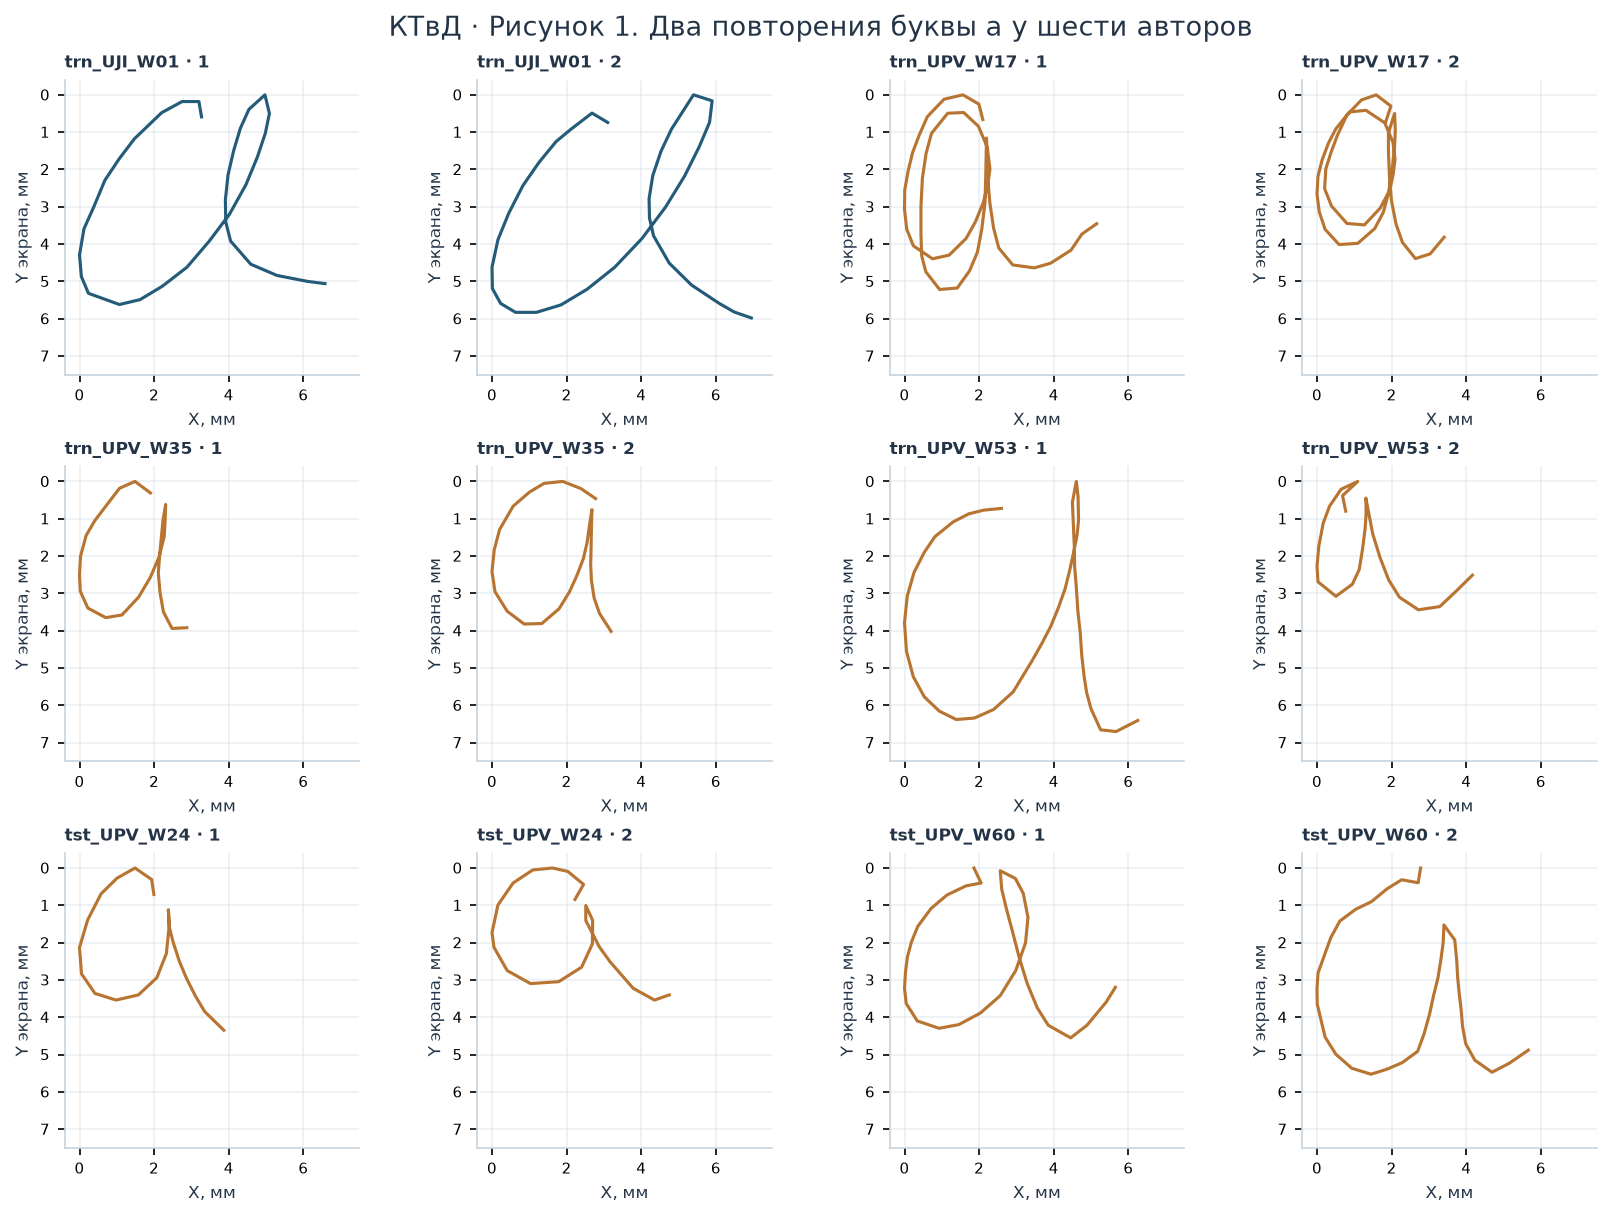

In [2]:
display(Image(filename=str(HERE / 'figures/hw01-examples.png')))

<a id="hw-eda" name="hw-eda"></a>

## 3 · Разведочный анализ

**Таблица КТвД 1 · Все 120 записей.** Значения округлены до трёх знаков. Для дисперсии и стандартного отклонения используется делитель $n-1$. Квантили вычислены линейной интерполяцией. В строке мод указаны все значения с наибольшей частотой.

















Ширина изменяется от 1,842 до 10,046 мм, высота — от 2,408 до 9,987 мм. Средняя ширина равна 5,094 мм, средняя высота — 4,610 мм. На гистограммах виден правый хвост и отдельные крупные знаки; такие записи сохранены в расчёте. Моды зависят от дискретности координат и не являются подбором теоретического закона.

У 60 из 60 авторов ширина двух повторений различается, у 60 различается высота. Медианы абсолютных различий равны соответственно 0,855 и 0,850 мм. Вариация есть и внутри одного автора.


In [3]:
display(pd.DataFrame(statistic_rows(result, 'glyphs'), columns=['Показатель','Ширина W','Высота H']))

,Показатель,Ширина W,Высота H
0,"Объём, записей",120,120
1,"Сумма, мм","611,286","553,214"
2,"Среднее, мм","5,094","4,610"
3,"Медиана, мм","5,000","4,378"
4,"Минимум, мм","1,842","2,408"
5,"Максимум, мм","10,046","9,987"
6,"Стандартное отклонение, мм","1,377","1,224"
7,"Выборочная дисперсия, мм²","1,897","1,498"
8,"5-й перцентиль, мм","2,953","3,157"
9,"1-й квартиль, мм","4,155","3,794"


**Рисунок КТвД 2 · Гистограммы и эмпирические функции распределения.** Границы столбцов выбраны правилом Фридмана—Диакониса. ECDF построены по исходным размерам без округления; ступени правосторонне непрерывны.



$$\widehat F_n(t)=\frac{1}{n}\sum_{j=1}^n\mathbf 1\{Z_j\leq t\},\qquad Z\in\{W,H\}.$$


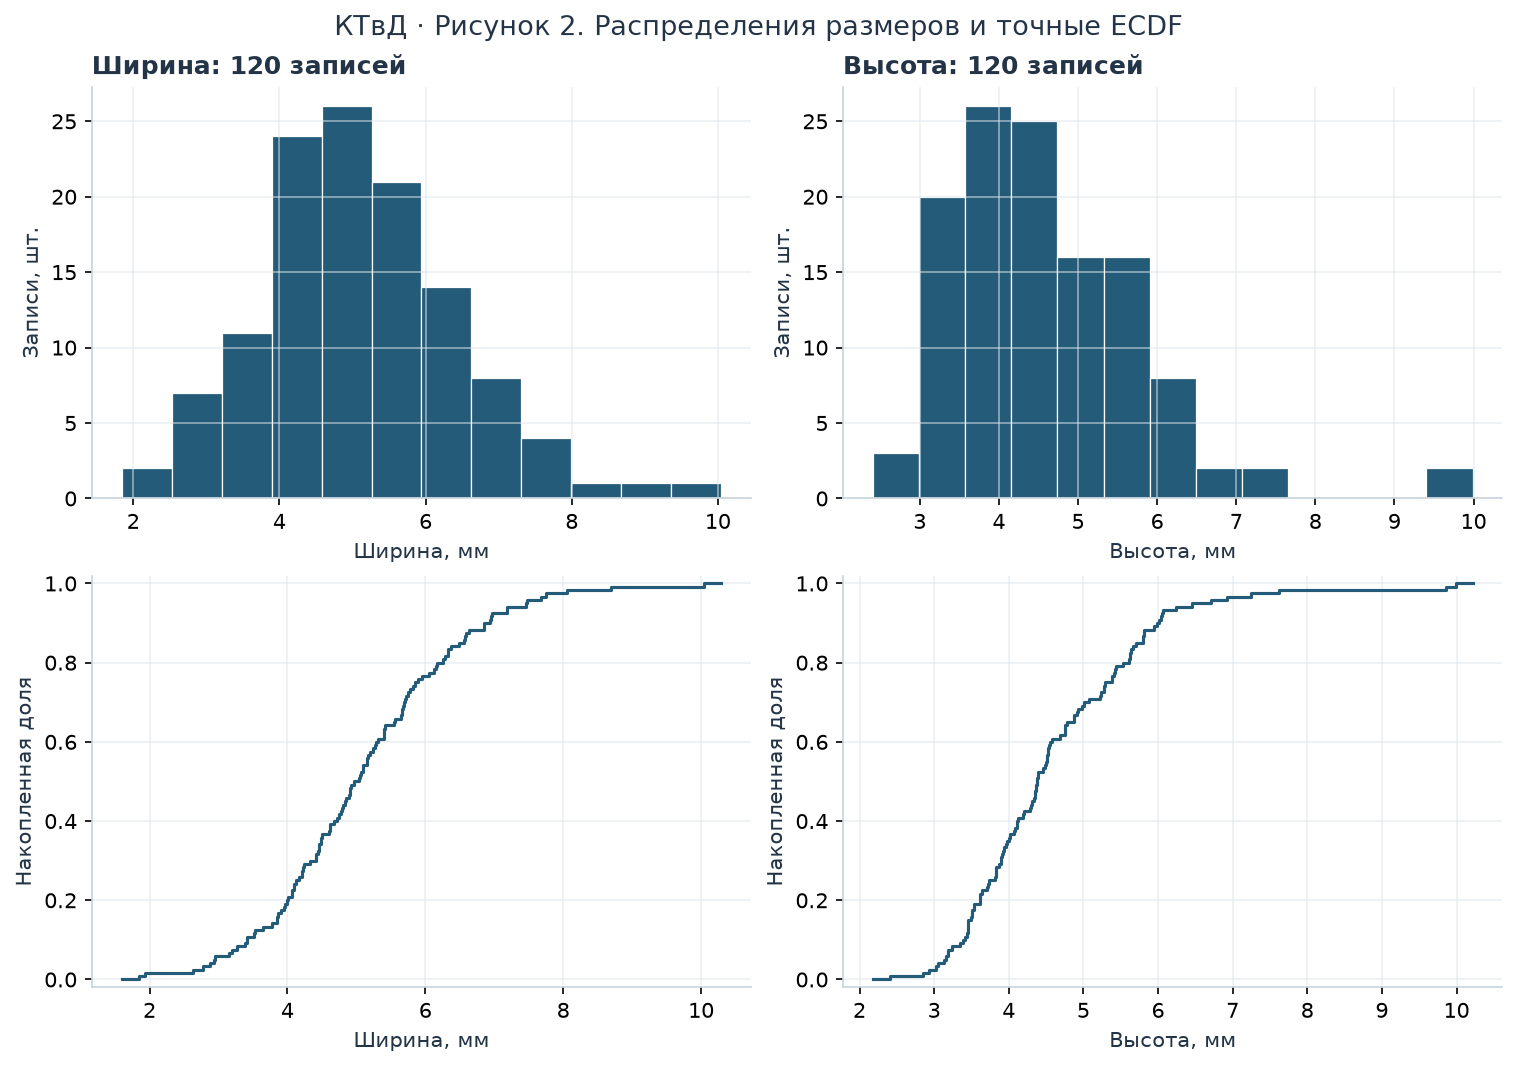

In [4]:
display(Image(filename=str(HERE / 'figures/hw02-distributions.png')))

Два повторения одного человека могут быть зависимы из-за общего почерка. Поэтому 120 записей не считаются 120 независимыми авторами. Для проверки межавторской связи используется по одной паре средних на человека:

$$\bar W_i=\frac{W_{i1}+W_{i2}}{2},\qquad\bar H_i=\frac{H_{i1}+H_{i2}}{2}.$$

**Таблица КТвД 2 · 60 пар авторских средних.** Средние ширина и высота рассчитаны по двум повторениям каждого автора.


















In [5]:
display(pd.DataFrame(statistic_rows(result, 'writers'), columns=['Показатель','Средняя ширина автора','Средняя высота автора']))

,Показатель,Средняя ширина автора,Средняя высота автора
0,"Объём, авторов",60,60
1,"Сумма, мм","305,643","276,607"
2,"Среднее, мм","5,094","4,610"
3,"Медиана, мм","4,992","4,526"
4,"Минимум, мм","2,237","3,055"
5,"Максимум, мм","8,188","8,553"
6,"Стандартное отклонение, мм","1,223","1,038"
7,"Выборочная дисперсия, мм²","1,495","1,077"
8,"5-й перцентиль, мм","3,214","3,239"
9,"1-й квартиль, мм","4,334","3,923"


**Рисунок КТвД 3 · Парные размеры.** Слева — все записи и соединённые повторы каждого автора, справа — 60 авторских средних. Оси обоих графиков имеют одинаковые пределы и единицы.




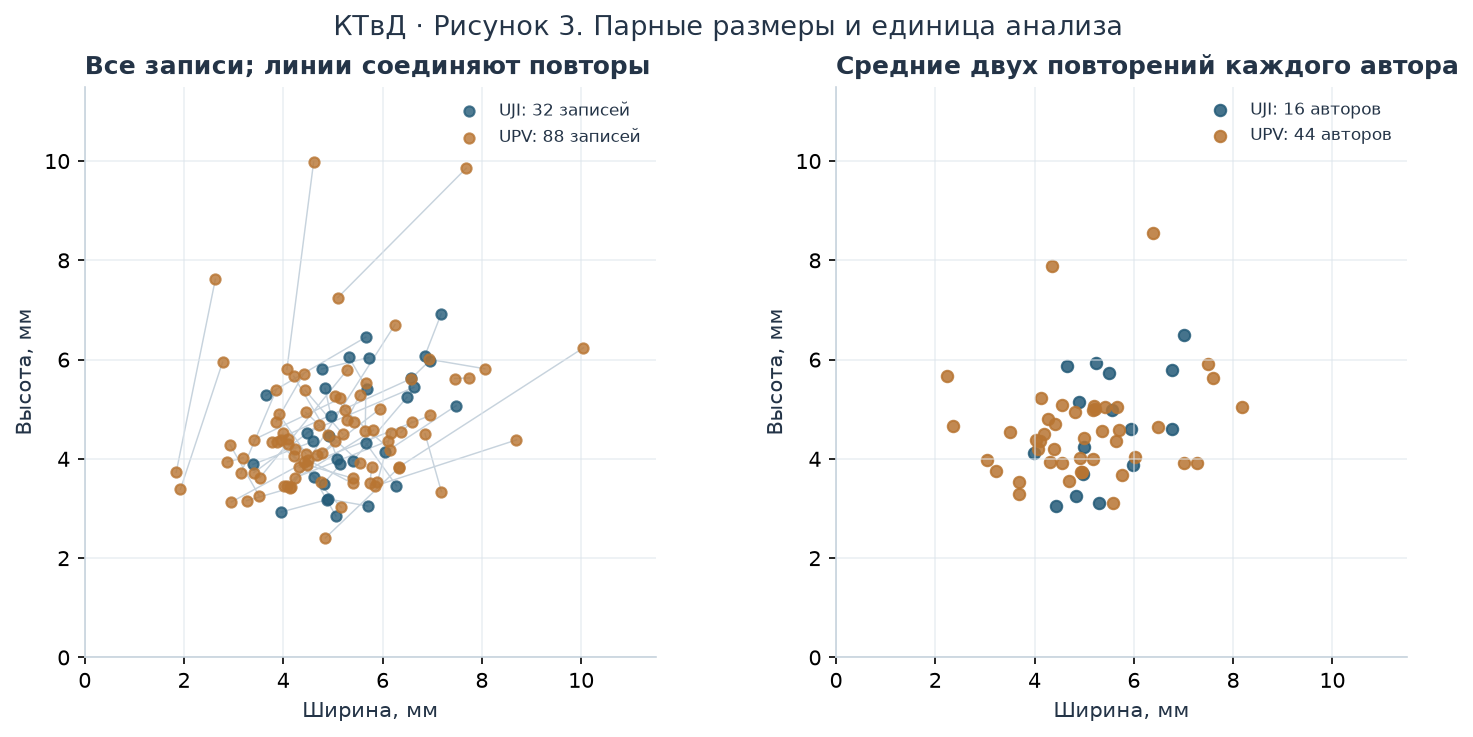

In [6]:
display(Image(filename=str(HERE / 'figures/hw03-pairs.png')))

<a id="hw-association" name="hw-association"></a>

## 4 · Проверка связи с учётом площадки

Обе величины относятся к одной записи, поэтому их независимость заранее не предполагается. Сначала приведены описательные коэффициенты. Различия в составе участников и условиях площадок могут сохраняться даже после перевода шкал в мм.

Основная проверка относится к **средним размерам авторов**. $H_0$: средняя ширина и средняя высота условно независимы при фиксированной площадке, $\bar W\perp\bar H\mid S$; соответствие ширин и высот внутри каждой площадки обменно; выбранная статистика чувствительна к ранговой связи. Альтернатива — связь, нарушающая это предположение.

Всем 60 средним присваиваются ранги $R_i$ и $Q_i$; совпадения получают средний ранг. Из рангов вычитаются средние ранги своей площадки:

$$u_i=R_i-\overline R_{s(i)},\qquad v_i=Q_i-\overline Q_{s(i)},\qquad
r_{rank\mid S}=\frac{\sum_i u_i v_i}{\sqrt{\sum_i u_i^2\sum_i v_i^2}}.$$

Высоты авторов переставляются только внутри UJI и внутри UPV, ширины остаются на месте. При $B=19999$ двустороннее Monte Carlo p вычисляется с поправкой для конечного числа перестановок:

$$p_{MC}=\frac{1+\#\{|r^{(b)}|\geq |r_{obs}|\}}{B+1}.$$

Для 95% percentile bootstrap-интервала 10 000 раз выбираются с возвращением целые пары авторских средних отдельно внутри площадок. Числа авторов 16 и 44 сохраняются; ранги пересчитываются заново. Интервал приближённый и рассчитан при сохранении состава выборки по площадкам.


**Таблица КТвД 3 · Коэффициенты связи и результаты проверки гипотезы.**









**Таблица КТвД 4 · Описательная чувствительность к площадке, единые мм.**






In [7]:
display(pd.DataFrame(association_rows(result), columns=['Показатель','Значение']))
display(pd.DataFrame(site_rows(result), columns=['Площадка','Авторы','Записи','Спирмен']))

,Показатель,Значение
0,"Спирмен: исходные ink units, 60 авторов","0,462946"
1,"Спирмен: единые мм, 60 авторов","0,221446"
2,"Пирсон: единые мм, 60 авторов","0,228703"
3,Частная ранговая корреляция с учётом площадки,"0,214832"
4,Двустороннее перестановочное p,"0,0906"
5,95% bootstrap-интервал,"[-0,042782; 0,453239]"


,Площадка,Авторы,Записи,Спирмен
0,UJI,16,32,"0,402798"
1,UPV,44,88,"0,170901"


**Рисунок КТвД 4 · Влияние масштаба.** Без пересчёта единиц pooled-корреляция Спирмена равна 0,463, после пересчёта — 0,221. Сравнение исходных ink units смешивало разные шкалы и завышало видимую связь. Перевод единиц учитывает разницу масштабов; при проверке связи также учитывается площадка.




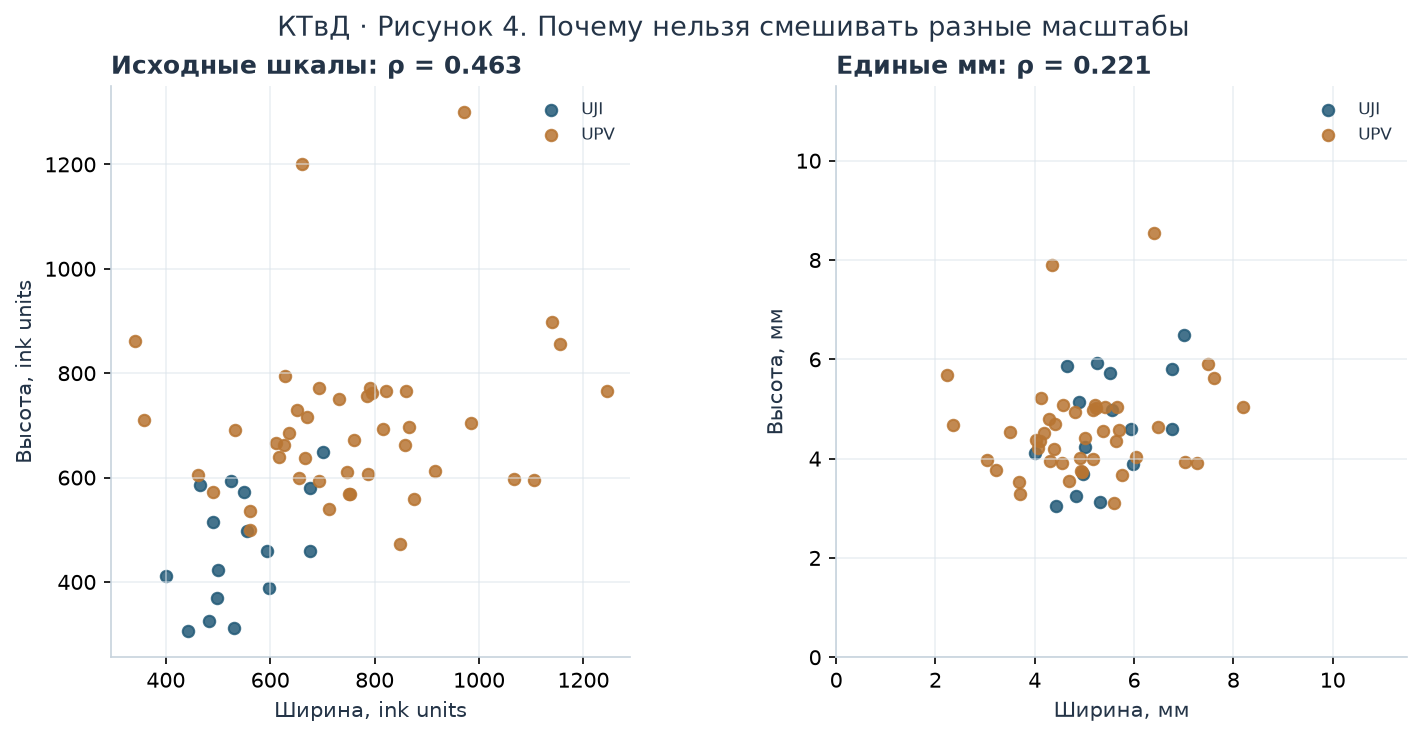

In [8]:
display(Image(filename=str(HERE / 'figures/hw04-calibration.png')))

**Рисунок КТвД 5 · Перестановочная проверка и bootstrap.** Частная ранговая оценка равна 0,214832. Более экстремальных перестановок — 1811 из 19999; p = 0,0906. Оценка Monte Carlo стандартной ошибки p составляет около 0,0020.



При $\alpha=0,05$ нулевая гипотеза **не отвергается**. Данный ранговый тест не дал достаточных оснований против условной независимости внутри площадок. **Независимость не доказана**: возможны другие виды связи и недостаточная точность выборки из 60 авторов. Интервал [-0,042782; 0,453239] включает ноль.


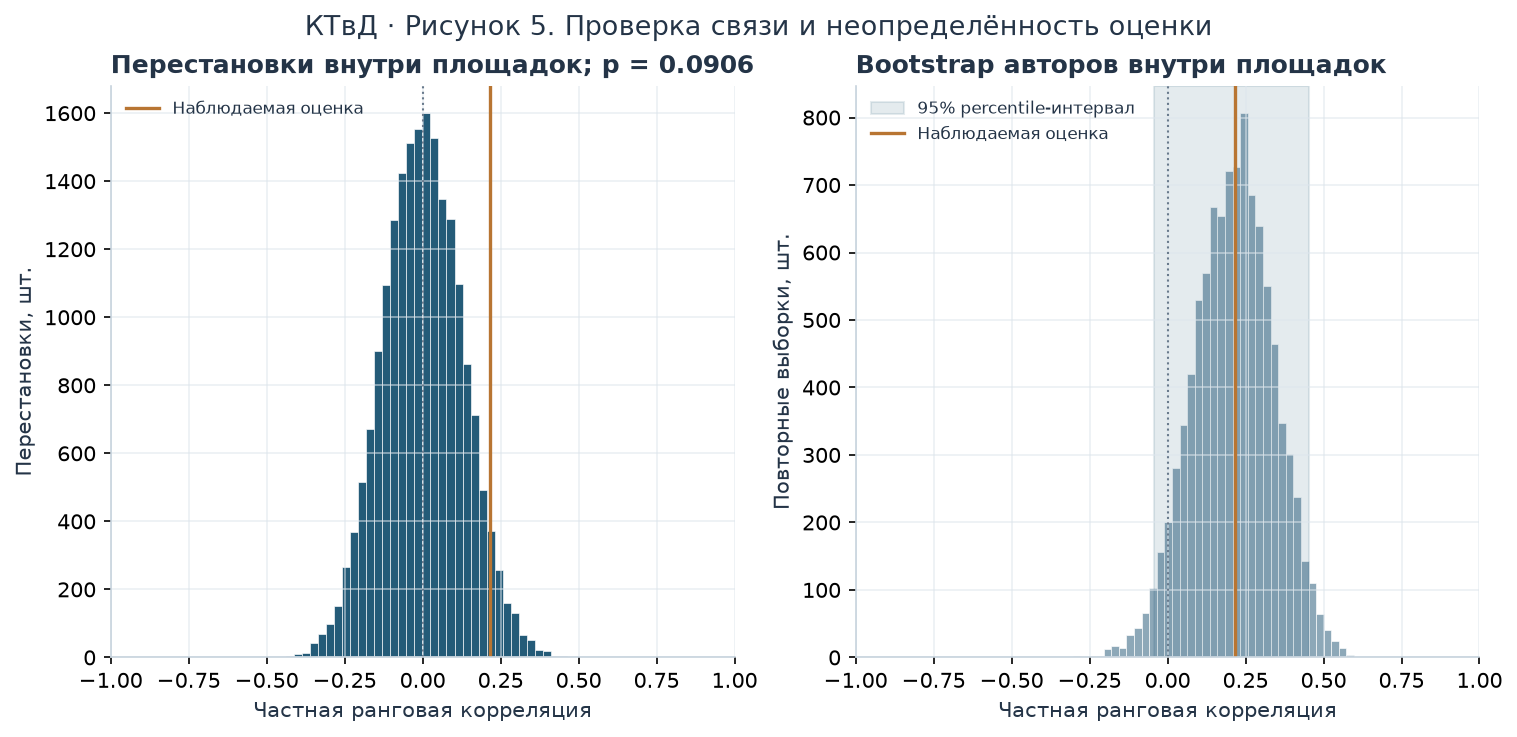

In [9]:
display(Image(filename=str(HERE / 'figures/hw05-uncertainty.png')))

<a id="hw-conclusions" name="hw-conclusions"></a>

## 5 · Выводы и ограничения

1. Для одинаковой буквы размеры не фиксированы: средние по всем записям составили 5,094 мм по ширине и 4,610 мм по высоте. Различия есть между авторами и между двумя повторениями одного автора.
2. При объединении рукописных данных сначала нужно согласовать единицы. Разные масштабы площадок заметно увеличивали наблюдаемую корреляцию. После документированного пересчёта и учёта площадки оценка связи слабая: 0,215, p = 0,0906.
3. При уровне 0,05 статистически значимая ранговая связь **между средними размерами авторов** не обнаружена. Это не равносильно доказанной независимости ширины и высоты отдельных букв.
4. Все описательные числа относятся к 120 принятым записям `a` данного набора. Авторы не описаны как случайная выборка населения. P-value и интервал требуют условной обменности/независимости участников внутри площадок; bootstrap не устраняет ограничение способа набора людей.
5. Участники писали в направляющих рамках и могли переделывать неудачные записи. Поэтому результаты относятся к принятым записям на планшете, а не к свободному письму на бумаге. Данных о времени и давлении нет, и эти характеристики не исследовались.




<a id="hw-sources" name="hw-sources"></a>

## 6 · Источники

1. Prat F., Castro M., Llorens D., Marzal A., Vilar J. **UJI Pen Characters (Version 2)**. UCI Machine Learning Repository, 2008. [DOI: 10.24432/C5FG8S](https://doi.org/10.24432/C5FG8S). Данные используются по [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); изменения — отбор `a`, расчёт размеров и перевод в мм.
2. Llorens D. et al. **The UJIpenchars Database: a Pen-Based Database of Isolated Handwritten Characters**. LREC, 2008. [Первичная статья](https://aclanthology.org/L08-1467/).
3. SciPy. [Перестановочные проверки, парные перестановки и Monte Carlo поправка](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).

[Данные](data/glyphs.csv) · [Средние по авторам](data/writer_means.csv)

[К оглавлению](#hw-top) · [Основная лабораторная работа](https://github.com/EastC0ast/lab01/tree/design-layout)
